# 05. Локализация частиц

Сравнение полного кадра и тайлов на одинаковых весах. Данные реальные, класс — `particle`.
Частица определяется по различимому телу независимо от покрытия.
Разметка предварительная; непокрытые частицы могут быть пропущены.


In [2]:
from pathlib import Path
import hashlib
import json
import os
import platform
import random
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
import torch
from torchvision.ops import box_iou, nms
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent
DATA = ROOT / 'data_real'
SETTINGS = dict(run_name='two_stage_20261024/localization', run_training=False,
                epochs=50, patience=20, batch=4, image_size=1024, device=None,
                train_minutes=54, fallback_minutes=3)
SETTINGS.update(globals().get('LOCALIZATION_OVERRIDES', {}))
# Запас до часа нужен для сохранения и проверки весов.
SETTINGS['train_minutes'] = min(54.0, max(0.01, float(SETTINGS['train_minutes'])))
SETTINGS['fallback_minutes'] = min(3.0, max(0.01, float(SETTINGS['fallback_minutes'])))
RUN_NAME = SETTINGS['run_name']
OUT = ROOT / 'models' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(OUT / 'ultralytics')
Path(os.environ['YOLO_CONFIG_DIR']).mkdir(parents=True, exist_ok=True)
from ultralytics import YOLO
import ultralytics

SEED = 42
DEVICE = SETTINGS['device'] if SETTINGS['device'] is not None else (0 if torch.cuda.is_available() else 'cpu')
IMAGE_SIZE, MAX_DET = SETTINGS['image_size'], 1000
AP_CONF, COUNT_CONF, MERGE_IOU = 0.001, 0.25, 0.5
TILE_SIZES, OVERLAP = (512, 768), 0.25
RUN_TRAINING = SETTINGS['run_training']
EPOCHS, PATIENCE, BATCH = SETTINGS['epochs'], SETTINGS['patience'], SETTINGS['batch']
REUSE_WEIGHTS = ROOT / 'models/clear_real_baseline/weights/best.pt'
INITIAL_WEIGHTS = ROOT / 'research/yolo26s.pt'
SELECTION = OUT / 'selected_pipeline.json'
if SELECTION.exists():
    previous_pipeline = json.loads(SELECTION.read_text(encoding='utf-8'))
    REUSE_WEIGHTS = ROOT / previous_pipeline['weights']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Creating new Ultralytics Settings v0.0.6 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\models\two_stage_20261024\localization\ultralytics\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 1. Данные

Train — D03/D04, val — D01/D02, test — D05. Тайлы используются при предсказании.
Отпечаток данных учитывает изображения, TXT и выборки.
D05 уже использовалась; для независимой проверки нужны новые кадры.


In [3]:
GROUPS = {'train': {'D03', 'D04'}, 'val': {'D01', 'D02'}, 'test': {'D05'}}
EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
records, digest = [], hashlib.sha256()
for split, groups in GROUPS.items():
    for path in sorted((DATA / 'images' / split).iterdir()):
        if path.suffix.lower() not in EXTENSIONS:
            continue
        group = path.stem.split('_')[0]
        if group not in groups:
            raise ValueError(f'Нарушено разделение групп: {path}')
        label = DATA / 'labels' / split / f'{path.stem}.txt'
        image_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        label_hash = hashlib.sha256(label.read_bytes()).hexdigest()
        digest.update(f'{split}/{path.name}:{image_hash}:{label_hash}'.encode())
        with Image.open(path) as image:
            width, height = image.size
        rows = np.loadtxt(label, ndmin=2).reshape(-1, 5)
        xywh = rows[:, 1:] * np.array([width, height, width, height])
        boxes = np.column_stack((xywh[:, :2] - xywh[:, 2:] / 2,
                                 xywh[:, :2] + xywh[:, 2:] / 2)).astype(np.float32)
        records.append(dict(image_id=path.stem, path=path, split=split, group=group,
                            width=width, height=height, boxes=boxes,
                            image_sha256=image_hash, label_sha256=label_hash))
DATA_HASH = digest.hexdigest()
metadata = dict(data_sha256=DATA_HASH, seed=SEED, groups={k: sorted(v) for k, v in GROUPS.items()},
                python=platform.python_version(), torch=torch.__version__,
                ultralytics=ultralytics.__version__, image_size=IMAGE_SIZE,
                tile_sizes=TILE_SIZES, overlap=OVERLAP, merge_iou=MERGE_IOU,
                ap_conf=AP_CONF, count_conf=COUNT_CONF, max_det=MAX_DET, training_settings=SETTINGS)
manifest = OUT / 'data_manifest.json'
if manifest.exists() and json.loads(manifest.read_text(encoding='utf-8'))['data_sha256'] != DATA_HASH:
    raise ValueError('Данные изменились: требуется новый RUN_NAME.')
manifest.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
inventory = pd.DataFrame([{k: v for k, v in r.items() if k not in ('boxes', 'path')}
                          | {'objects': len(r['boxes'])} for r in records])
display(inventory.groupby(['split', 'group']).agg(images=('image_id', 'count'), objects=('objects', 'sum')))
print('SHA256:', DATA_HASH)

images  objects
split group                 
test  D05         3      101
train D03        15      504
      D04         9      439
val   D01         2       91
      D02         2      132

SHA256: ee580bc0e3b5f2fa26aadd63c83d8b3642adff64f690b75c3dd8015f9f1c0fbb


## 2. Обучение и веса

`RUN_TRAINING=False` загружает сохранённую модель, `True` запускает обучение из YOLO26s.
При первом запуске без обучения используются прежние веса real/baseline.
Лимит обучения — 54 минуты; при остановке — сохранение весов и облегчённый запуск до 3 минут.


In [4]:
def train_detector(checkpoint, name, minutes, **changes):
    if (OUT / name).exists():
        raise FileExistsError('Запуск уже существует; измените RUN_NAME.')
    config = OUT / 'dataset.yaml'
    config.write_text(yaml.safe_dump(dict(path=DATA.as_posix(), train='images/train',
        val='images/val', test='images/test', names={0: 'particle'})), encoding='utf-8')
    args = dict(data=str(config), project=str(OUT), name=name,
        epochs=EPOCHS, patience=PATIENCE, imgsz=IMAGE_SIZE, batch=BATCH, time=None,
        device=DEVICE, workers=0, seed=SEED, deterministic=True,
        optimizer='auto', pretrained=True, cache=False, plots=False, max_det=MAX_DET,
        hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=10.0, translate=0.05,
        scale=0.15, fliplr=0.5, flipud=0.5, mosaic=0.0, mixup=0.0, close_mosaic=0)
    args.update(changes)
    model = YOLO(str(checkpoint), task='detect')
    begin = time.perf_counter()
    clock = {'timeout': False}

    def time_guard(trainer):
        if time.perf_counter() - begin >= minutes * 60:
            trainer.stop = True
            clock['timeout'] = True

    model.add_callback('on_train_batch_end', time_guard)
    model.add_callback('on_train_epoch_end', time_guard)
    try:
        model.train(**args)
    except Exception as error:
        failure = dict(status='failed', reason=repr(error), elapsed_seconds=time.perf_counter() - begin,
                       checkpoint=str(checkpoint), args=args)
        (OUT / f'{name}_status.json').write_text(json.dumps(failure, indent=2), encoding='utf-8')
        raise
    elapsed = time.perf_counter() - begin
    directory = Path(model.trainer.save_dir)
    history = pd.read_csv(directory / 'results.csv')
    timed_out = clock['timeout'] or (elapsed >= minutes * 60 - 5 and len(history) < args['epochs'])
    status = dict(status='time_limited' if timed_out else ('completed' if len(history) >= args['epochs'] else 'early_stopped'),
        elapsed_seconds=elapsed, epochs_completed=len(history), epochs_requested=args['epochs'],
        reason='wall_clock_budget' if timed_out else None, args=args,
        weights=(directory / 'weights/best.pt').relative_to(ROOT).as_posix())
    (OUT / f'{name}_status.json').write_text(json.dumps(status, indent=2), encoding='utf-8')
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return directory / 'weights/best.pt', status


if RUN_TRAINING:
    WEIGHTS, train_status = train_detector(INITIAL_WEIGHTS, 'full_train', SETTINGS['train_minutes'])
    if train_status['status'] == 'time_limited':
        WEIGHTS, fallback_status = train_detector(WEIGHTS, 'fallback768', SETTINGS['fallback_minutes'],
            imgsz=768, epochs=25, patience=8, batch=min(BATCH, 4), nbs=16)
        print('Облегчённая попытка:', fallback_status['status'])
    print('Исходное обучение:', train_status['status'])
else:
    WEIGHTS = REUSE_WEIGHTS
detector = YOLO(str(WEIGHTS), task='detect')
WEIGHT_HASH = hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()
print('Веса:', WEIGHTS.relative_to(ROOT), '| SHA256:', WEIGHT_HASH)

New https://pypi.org/project/ultralytics/8.4.185 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12199MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\models\two_stage_20261024\localization\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\research\yolo26s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=full_train, nbs=64, nms=False, opset=None, optimize=False, optim

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


...

YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 11.1it/s 0.1s

                   all          4        223      0.811       0.74      0.794      0.526


Speed: 0.2ms preprocess, 4.0ms inference, 0.0ms loss, 0.1ms postprocess per image


Исходное обучение: completed
Веса: models\two_stage_20261024\localization\full_train\weights\best.pt | SHA256: 752046cac48cc9e67709c57769ace8be256a38f347ea6e96067fa0a736e3f3c7


## 3. Полный кадр и тайлы

Тайлы перекрываются на 25%. Общий NMS убирает дубли после возврата координат в исходный кадр.
Обрезанные объекты на внутренних границах тайлов отбрасываются. Полный кадр сохраняет крупные частицы.


In [5]:
def starts(length, size, overlap):
    if length <= size:
        return [0]
    step = max(1, round(size * (1 - overlap)))
    return sorted(set([*range(0, length - size + 1, step), length - size]))


def raw_predict(image):
    result = detector.predict(image, imgsz=IMAGE_SIZE, conf=AP_CONF, iou=0.7,
        max_det=MAX_DET, device=DEVICE, rect=True, augment=False, half=False,
        verbose=False, save=False)[0]
    return torch.cat((result.boxes.xyxy.cpu(), result.boxes.conf.cpu()[:, None]), dim=1)


def predict_frame(path, tile_size=None):
    image = Image.open(path).convert('RGB')
    width, height = image.size
    predictions = [raw_predict(image)]
    if tile_size:
        for y in starts(height, tile_size, OVERLAP):
            for x in starts(width, tile_size, OVERLAP):
                x2, y2 = min(x + tile_size, width), min(y + tile_size, height)
                boxes = raw_predict(image.crop((x, y, x2, y2)))
                if not len(boxes):
                    continue
                margin = 3
                complete = torch.ones(len(boxes), dtype=torch.bool)
                if x > 0:
                    complete &= boxes[:, 0] > margin
                if y > 0:
                    complete &= boxes[:, 1] > margin
                if x2 < width:
                    complete &= boxes[:, 2] < x2 - x - margin
                if y2 < height:
                    complete &= boxes[:, 3] < y2 - y - margin
                boxes = boxes[complete]
                boxes[:, :4] += torch.tensor([x, y, x, y])
                predictions.append(boxes)
    boxes = torch.cat(predictions)
    if len(boxes):
        boxes = boxes[nms(boxes[:, :4], boxes[:, 4], MERGE_IOU)[:MAX_DET]]
    return boxes.numpy()

## 4. Метрики

AP: 101 точка recall, IoU 0.50–0.95. Precision, recall и F1: `COUNT_CONF`, IoU 0.50.
Размер bbox — корень из площади при ширине кадра 1024 px; это размер в пикселях.
Recall по размерам учитывает пропуски; AP рассчитывается по всем размерам.


In [6]:
IOU_LEVELS = np.linspace(0.5, 0.95, 10)


def match_predictions(predictions, gt, threshold):
    # Одна детекция и один GT участвуют не более одного раза.
    predictions = predictions[np.argsort(-predictions[:, 4], kind='stable')]
    matched = np.full(len(predictions), -1, dtype=int)
    if not len(predictions) or not len(gt):
        return predictions, matched
    ious = box_iou(torch.tensor(predictions[:, :4]), torch.tensor(gt)).numpy()
    used = set()
    for index, overlaps in enumerate(ious):
        for target in np.argsort(-overlaps):
            if overlaps[target] < threshold:
                break
            if int(target) not in used:
                matched[index] = target
                used.add(int(target))
                break
    return predictions, matched


def evaluate_predictions(predictions_by_id, split):
    samples = [r for r in records if r['split'] == split]
    total = sum(len(r['boxes']) for r in samples)
    ap_values = []
    for threshold in IOU_LEVELS:
        scored = []
        for sample in samples:
            pred, matches = match_predictions(predictions_by_id[sample['image_id']], sample['boxes'], threshold)
            scored.extend(zip(pred[:, 4], matches >= 0))
        scored.sort(key=lambda p: -p[0])
        flags = np.array([p[1] for p in scored], dtype=float)
        recall = flags.cumsum() / max(total, 1)
        precision = flags.cumsum() / np.arange(1, len(flags) + 1)
        ap_values.append(np.mean([precision[recall >= point].max(initial=0)
                                 for point in np.linspace(0, 1, 101)]))
    frame_rows, size_rows = [], []
    for sample in samples:
        gt = sample['boxes']
        pred = predictions_by_id[sample['image_id']]
        pred, matches = match_predictions(pred[pred[:, 4] >= COUNT_CONF], gt, 0.5)
        tp = int((matches >= 0).sum())
        fp, fn = len(pred) - tp, len(gt) - tp
        frame_rows.append(dict(image_id=sample['image_id'], group=sample['group'],
            gt=len(gt), predicted=len(pred), tp=tp, fp=fp, fn=fn,
            precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
            absolute_count_error=abs(len(pred) - len(gt))))
        side = np.sqrt(np.prod(gt[:, 2:] - gt[:, :2], axis=1)) * 1024 / sample['width']
        detected = set(matches[matches >= 0])
        for index, value in enumerate(side):
            size_rows.append(dict(image_id=sample['image_id'],
                size='small' if value < 32 else ('medium' if value < 96 else 'large'),
                normalized_side=float(value), detected=int(index in detected)))
    frames, sizes = pd.DataFrame(frame_rows), pd.DataFrame(size_rows)
    tp, fp, fn = (int(frames[key].sum()) for key in ('tp', 'fp', 'fn'))
    metrics = dict(map50=float(ap_values[0]), map50_95=float(np.mean(ap_values)),
        precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
        f1=2 * tp / max(2 * tp + fp + fn, 1), count_mae=float(frames.absolute_count_error.mean()),
        gt=total, tp=tp, fp=fp, fn=fn)
    return metrics, frames, sizes


def run_comparison(split, variants):
    rows, predictions = [], {}
    for variant, tile_size in variants.items():
        begin = time.perf_counter()
        current = {r['image_id']: predict_frame(r['path'], tile_size)
                   for r in records if r['split'] == split}
        values, frames, sizes = evaluate_predictions(current, split)
        rows.append(dict(variant=variant, split=split, seconds=time.perf_counter() - begin, **values))
        frames.to_csv(OUT / f'{split}_{variant}_frames.csv', index=False)
        sizes.groupby('size').agg(gt=('detected', 'count'), recall=('detected', 'mean')).to_csv(
            OUT / f'{split}_{variant}_sizes.csv')
        flat = [dict(image_id=name, x1=float(b[0]), y1=float(b[1]), x2=float(b[2]),
                     y2=float(b[3]), confidence=float(b[4])) for name, boxes in current.items() for b in boxes]
        pd.DataFrame(flat, columns=['image_id', 'x1', 'y1', 'x2', 'y2', 'confidence']).to_csv(
            OUT / f'{split}_{variant}_predictions.csv', index=False)
        predictions[variant] = current
    return pd.DataFrame(rows), predictions

## 5. Выбор на val

Сравнение трёх схем предсказания на одних весах.
AP рассчитан общим кодом для всех схем и может отличаться от отчёта Ultralytics.


In [7]:
VARIANTS = {'full': None, **{f'full_tiles{size}': size for size in TILE_SIZES}}
val_comparison, val_predictions = run_comparison('val', VARIANTS)
val_comparison.to_csv(OUT / 'val_comparison.csv', index=False)
display(val_comparison.sort_values('map50_95', ascending=False).round(4))
selected = val_comparison.sort_values(['map50_95', 'f1'], ascending=False).iloc[0]
selected_name = selected['variant']
pipeline = dict(variant=selected_name, tile_size=VARIANTS[selected_name], overlap=OVERLAP,
    merge_iou=MERGE_IOU, imgsz=IMAGE_SIZE, max_det=MAX_DET, ap_conf=AP_CONF,
    confidence=COUNT_CONF, weights=WEIGHTS.relative_to(ROOT).as_posix(),
    weight_sha256=WEIGHT_HASH, data_sha256=DATA_HASH, seed=SEED)
SELECTION.write_text(json.dumps(pipeline, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.read_csv(OUT / f'val_{selected_name}_frames.csv').round(3))
display(pd.read_csv(OUT / f'val_{selected_name}_sizes.csv').round(3))

,variant,split,seconds,map50,map50_95,precision,recall,f1,count_mae,gt,tp,fp,fn
2,full_tiles768,val,0.3982,0.8832,0.5793,0.8962,0.8520,0.8736,3.75,223,190,22,33
1,full_tiles512,val,0.6483,0.8825,0.5515,0.8932,0.8251,0.8578,4.75,223,184,22,39
0,full,val,0.3494,0.8536,0.5299,0.8900,0.7982,0.8416,6.25,223,178,22,45


,image_id,group,gt,predicted,tp,fp,fn,precision,recall,absolute_count_error
0,D01_001_300um,D01,90,85,78,7,12,0.918,0.867,5
1,D01_009_30um,D01,1,2,1,1,0,0.500,1.000,1
2,D02_001_300um,D02,130,122,110,12,20,0.902,0.846,8
3,D02_003_30um,D02,2,3,1,2,1,0.333,0.500,1


,size,gt,recall
0,large,4,0.750
1,medium,211,0.886
2,small,8,0.000


## 6. Проверка на test

Оценка выбранной на val схемы. Зелёные рамки — разметка, красные — предсказания.
Метрики по кадрам и размерам сохраняются в CSV.


,variant,split,seconds,map50,map50_95,precision,recall,f1,count_mae,gt,tp,fp,fn
0,full_tiles768,test,0.7611,0.8284,0.4638,0.7961,0.8119,0.8039,2.0,101,82,21,19


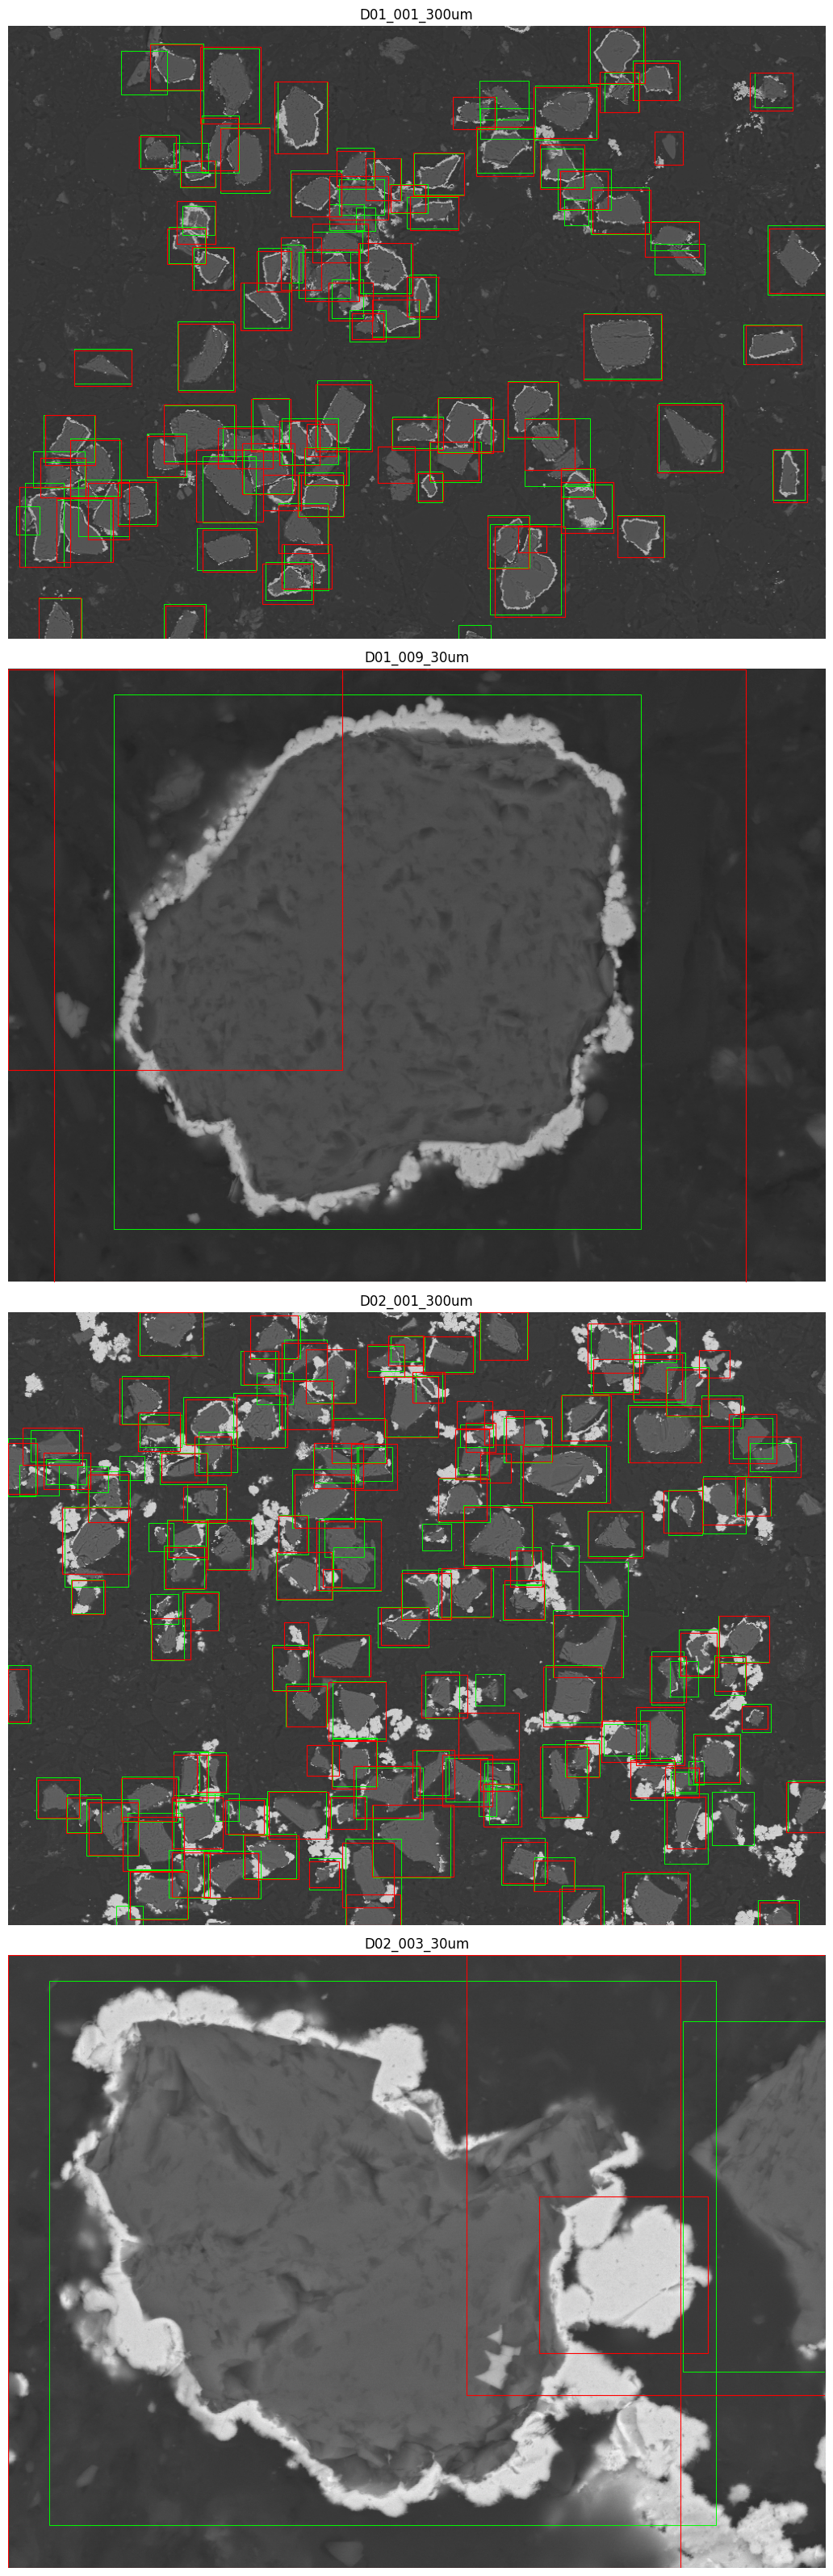

In [8]:
test_comparison, test_predictions = run_comparison('test', {selected_name: VARIANTS[selected_name]})
test_comparison.to_csv(OUT / 'test_comparison.csv', index=False)
display(test_comparison.round(4))
preview = [r for r in records if r['split'] == 'val']
fig, axes = plt.subplots(len(preview), 1, figsize=(14, 8 * len(preview)), squeeze=False)
for ax, sample in zip(axes.flat, preview):
    ax.imshow(Image.open(sample['path']))
    for box in sample['boxes']:
        ax.add_patch(Rectangle(box[:2], *(box[2:] - box[:2]), fill=False, color='lime', linewidth=0.7))
    for box in val_predictions[selected_name][sample['image_id']]:
        if box[4] >= COUNT_CONF:
            ax.add_patch(Rectangle(box[:2], *(box[2:4] - box[:2]), fill=False, color='red', linewidth=0.8))
    ax.set_title(sample['image_id'])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Кропы найденных частиц

Экспорт с 10% контекста и таблицей исходных кадров, групп, bbox и confidence.
Для обучения классификатора в 06 используются кропы по разметке, а не предсказанные рамки.


In [9]:
crop_dir = OUT / 'detected_crops'
crop_dir.mkdir(exist_ok=True)
crop_rows = []
for sample in records:
    source = Image.open(sample['path']).convert('RGB')
    boxes = predict_frame(sample['path'], VARIANTS[selected_name])
    for index, box in enumerate(boxes[boxes[:, 4] >= COUNT_CONF]):
        x1, y1, x2, y2 = map(float, box[:4])
        dx, dy = (x2 - x1) * 0.1, (y2 - y1) * 0.1
        bounds = (max(0, int(np.floor(x1 - dx))), max(0, int(np.floor(y1 - dy))),
                  min(source.width, int(np.ceil(x2 + dx))), min(source.height, int(np.ceil(y2 + dy))))
        crop_id = f"{sample['image_id']}__pred_{index:04d}"
        crop_path = crop_dir / f'{crop_id}.png'
        source.crop(bounds).save(crop_path)
        crop_rows.append(dict(crop_id=crop_id, crop=crop_path.relative_to(ROOT).as_posix(),
            source=sample['path'].relative_to(ROOT).as_posix(), source_sha256=sample['image_sha256'],
            split=sample['split'], group=sample['group'], image_id=sample['image_id'],
            x1=x1, y1=y1, x2=x2, y2=y2, crop_x1=bounds[0], crop_y1=bounds[1],
            crop_x2=bounds[2], crop_y2=bounds[3], detector_confidence=float(box[4]),
            detector_weights_sha256=WEIGHT_HASH, pipeline=selected_name))
pd.DataFrame(crop_rows).to_csv(OUT / 'detected_crops.csv', index=False)
print('Кропов:', len(crop_rows), '|', crop_dir.relative_to(ROOT))

Кропов: 1536 | models\two_stage_20261024\localization\detected_crops


## Источники

[SAHI](https://arxiv.org/abs/2202.06934) — предсказания по тайлам.
[DualSight](https://www.nature.com/articles/s41598-025-09642-3) — детекция и сегментация порошков на SEM-снимках.
В этом ноутбуке используются bbox и собственное объединение предсказаний.
